<img src="logo.png" alt="Vegeta" width="240">

# Svarog-fiber — a Yb fibre laser, designed on Hyperion

**Svarog-fiber** is the fibre twin of Svarog's rod (`46_svarog`): a 1070 nm continuous-wave laser whose cavity *is* the
gain medium — a 10/125 µm Yb-doped double-clad fibre between two fibre Bragg gratings, pumped at 976 nm by fibre-coupled
diodes through a combiner — followed by one amplifier stage in a 20/125 µm fibre. Everything is computed with Hyperion's
`fibre` module ([docs/hyperion.md](../docs/hyperion.md)): the fibres' modes, cutoffs and bend loss; the pump and the two
signal waves along the fibre from the rate equations, shot to the gratings' reflectivities; the amplifier's single pass; the
Raman threshold and the core's temperature. The device as numbers is `designs/svarog_fiber.py` (`import svarog_fiber as sf`);
the drawings `designs/svarog_fiber_drawings.py`. Notebook 46's record (`designs/data/reports/46_svarog.json`) is read for the
comparison with the rod at the same 20 W; when it is missing the comparison says so and shows the fibre alone.

The record goes to `designs/data/svarog_fiber_design.json` (the oscillator, the amplifier, the beam and the delivery train as
Hyperion objects) and `designs/data/reports/47_svarog_fiber.json`. Not here: ASE and the noise of a weak-seed preamplifier, the
higher-mode stripping of the few-mode amplifier fibre, pulses — `svarog_todo.md` S.5.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import fibre as fb
import svarog_fiber as sf, svarog_fiber_drawings as sfd, svarog_drawings as svd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
OUT = Path("output/47_svarog_fiber"); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("designs/data")
from vegeta import yanus
GATE = yanus.enter("47_svarog_fiber", debug=DEBUG)   # the door keeper: needs vegeta.hyperion, takes 46's report (optional), gives the design and the report
PUMP_OSC = 20.0                                      # W launched into the oscillator: Svarog's work point, for the comparison
PUMP_AMP = 50.0                                      # W launched into the amplifier (six 9 W diodes through the combiner)
R46_PATH = DATA / "reports" / "46_svarog.json"
R46 = json.loads(R46_PATH.read_text()) if R46_PATH.exists() else None
if R46 is None:
    print("WARNING: notebook 46's report is missing — the comparison with the rod will show the fibre alone; run 46_svarog first")

## 1. The fibres, their modes, the pumps

Two fibres: the oscillator's **10/125** (core Ø10 µm, NA 0.075 — single-mode at 1070 nm, V = 2.20) and the amplifier's
**20/125** (NA 0.06, V = 3.5: a few-mode fibre whose LP₁₁ a coil must strip). Marcuse's fit gives the LP₀₁ radius; the
overlap factors Γ_s (the mode inside the core) and Γ_p = (a/b)² (the cladding pump crossing the core) are what the rate
equations see. The doping is not a number the model picks: the datasheet's cladding absorption at 976 nm (1.7 and 5 dB/m)
sets the ion density. The pumps are 9 W diodes on 105/125 µm, NA 0.22 pigtails through a (6+1)×1 combiner — the étendue
check says how many fit the 125 µm, NA 0.46 cladding.

In [3]:
rows = {}
for f in (sf.FIBRE_OSC, sf.FIBRE_AMP):
    act = sf.active(f, 1.0)
    rows[f.name] = {"core Ø [µm]": 2 * f.core_radius * 1e6, "NA": f.NA, "clad Ø [µm]": 2 * f.clad_radius * 1e6, "V at 1070": f.V(sf.LAM), "V at 976": f.V(sf.LAM_P),
                    "single-mode at 1070": f.single_mode(sf.LAM), "cutoff [nm]": f.cutoff_wavelength * 1e9, "MFD at 1070 [µm]": 2 * f.mode_radius(sf.LAM) * 1e6,
                    "Γ_s": f.overlap_core(sf.LAM), "Γ_p": f.overlap_clad, "absorption at 976 [dB/m]": act.absorption_db_per_m(sf.LAM_P),
                    "absorption at 915 [dB/m]": act.absorption_db_per_m(915e-9), "Yb ions [1e25/m³]": act.dopant.N / 1e25,
                    "far-field half-angle [mrad]": f.beam(sf.LAM).divergence * 1e3}
FIB = pd.DataFrame(rows).T; display(FIB.round(3))
for pump, f in ((sf.PUMP_OSC, sf.FIBRE_OSC), (sf.PUMP_AMP, sf.FIBRE_AMP)):
    fit = pump.fits_the_cladding(f)
    print(f"{f.name}: {pump.n_diodes} × {pump.diode_W:g} W diodes → {pump.power_max:.1f} W launched at most; étendue: {fit['ports_that_fit']} ports fit, {fit['used']} used — {'ok' if fit['fits'] else 'does not fit'}")
sa, se = fb.YB_SILICA.cross_sections(sf.LAM_P); sas, ses = fb.YB_SILICA.cross_sections(sf.LAM)
print(f"Yb:silica — at 976 nm σ_a {sa:.2e}, σ_e {se:.2e} m²; at 1070 nm σ_a {sas:.1e}, σ_e {ses:.1e} m²; τ {fb.YB_SILICA.tau * 1e3:.2f} ms; quantum limit λ_p/λ_s = {sf.QUANTUM_LIMIT:.3f}")

,core Ø [µm],NA,clad Ø [µm],V at 1070,V at 976,single-mode at 1070,cutoff [nm],MFD at 1070 [µm],Γ_s,Γ_p,absorption at 976 [dB/m],absorption at 915 [dB/m],Yb ions [1e25/m³],far-field half-angle [mrad]
10/125 Yb double-clad,10.0,0.075,125.0,2.202051,2.414134,True,979.777535,11.707078,0.767592,0.0064,1.7,0.51,2.446497,58.185585
20/125 Yb double-clad,20.0,0.06,125.0,3.523281,3.862614,False,1567.644056,17.926264,0.917048,0.0256,5.0,1.5,1.798895,37.99917


10/125 Yb double-clad: 3 × 9 W diodes → 25.6 W launched at most; étendue: 6 ports fit, 3 used — ok
20/125 Yb double-clad: 6 × 9 W diodes → 51.3 W launched at most; étendue: 6 ports fit, 6 used — ok
Yb:silica — at 976 nm σ_a 2.50e-24, σ_e 2.50e-24 m²; at 1070 nm σ_a 8.0e-27, σ_e 2.8e-25 m²; τ 0.85 ms; quantum limit λ_p/λ_s = 0.912


## 2. The oscillator

The active fibre between the gratings (HR 99 % with 0.3 dB of splice and grating loss per pass folded in; OC 10 %), pumped
from the HR end. For each length Hyperion integrates the pump and both signal waves along z and shoots on the circulating
power until the backward wave at the coupler is R_oc times the forward one; the output is what the coupler lets through.
The length: the output rises while the fibre absorbs more pump and flattens once little is left — the rule is the shortest
fibre within 3 % of the best. The coupler: at this gain the output is flat from 4 % to 20 % reflectivity; 10 % keeps the
inversion and the circulating power moderate. Then the power evolution along the chosen fibre, the threshold (the
small-signal round trip reaching 1), the slope and the power curve up to the three diodes' 25.6 W.

length: the best 13 m gives 16.32 W; chosen 9 m (shortest within 3% of the best): 15.98 W, 0.84 W of pump unabsorbed  [4 s]


,output_W,threshold_W,circulating_at_OC_W,gain_db_one_way,inversion_max
R_oc,,,,,
0.04,16.276,0.274,16.954,7.312,0.159
0.07,16.126,0.249,17.340,6.096,0.132
0.10,15.982,0.232,17.758,5.322,0.117
0.15,15.744,0.214,18.523,4.441,0.101
0.20,15.502,0.201,19.378,3.817,0.090
0.30,14.981,0.183,21.402,2.936,0.075


oscillator at 20 W: output 15.98 W (80% of the launched pump, 91% of the quantum limit on the absorbed), threshold 0.23 W, slope 0.808; heat 2.14 W, peak 0.60 W/m; inversion 3.0%–11.7%


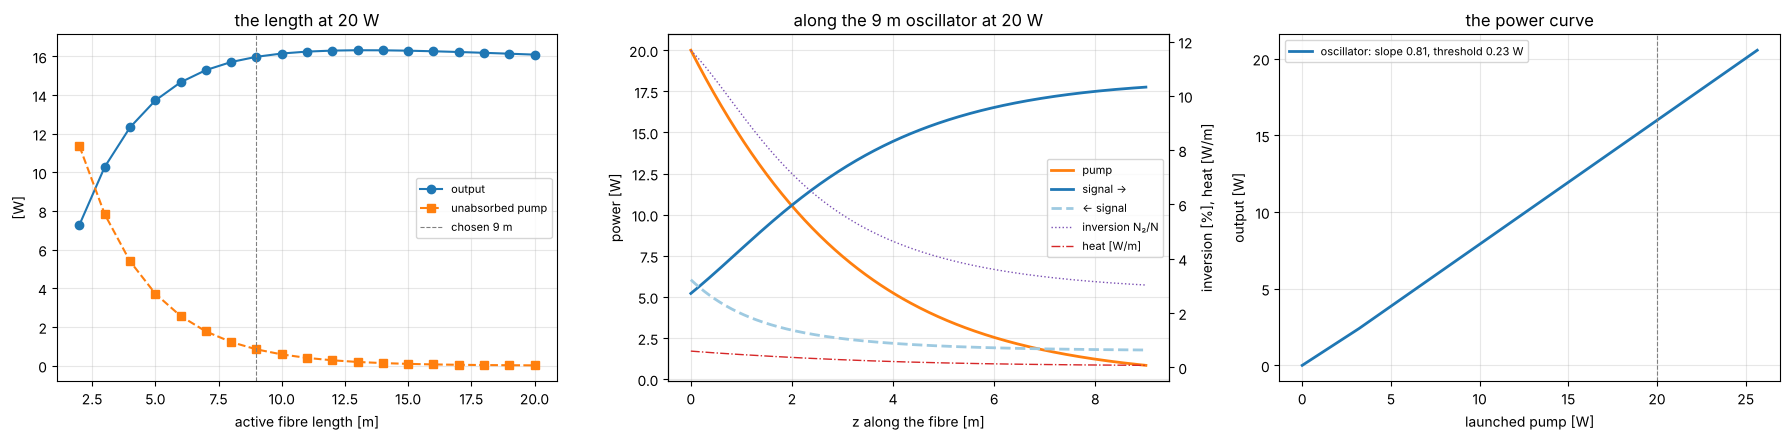

In [4]:
t0 = time.time()
LC = sf.length_choice(PUMP_OSC, n=sf.N_SWEEP)
LEN = LC["chosen_length"]
print(f"length: the best {LC['best_length']:g} m gives {LC['best_output_W']:.2f} W; chosen {LEN:g} m ({LC['rule']}): {LC['chosen_output_W']:.2f} W, {LC['chosen_unabsorbed_W']:.2f} W of pump unabsorbed  [{time.time() - t0:.0f} s]")
CC = pd.DataFrame(sf.coupler_choice(LEN, PUMP_OSC, n=sf.N_SWEEP)).T; CC.index.name = "R_oc"; display(CC.round(3))
OSC = sf.oscillator(LEN)
S_OSC = OSC.solve(PUMP_OSC, n=sf.N_FINE)
TH = OSC.threshold(n=sf.N_SWEEP)
PC = OSC.power_curve(np.linspace(0, sf.PUMP_OSC.power_max, 9), n=sf.N_SWEEP)
print(f"oscillator at {PUMP_OSC:.0f} W: output {S_OSC.output_W:.2f} W ({S_OSC.efficiency:.0%} of the launched pump, {S_OSC.output_W / S_OSC.absorbed_W / sf.QUANTUM_LIMIT:.0%} of the quantum limit on the absorbed), "
      f"threshold {TH:.2f} W, slope {PC['slope']:.3f}; heat {S_OSC.heat_W:.2f} W, peak {S_OSC.peak_heat_per_m:.2f} W/m; inversion {S_OSC.inversion.min():.1%}–{S_OSC.inversion.max():.1%}")
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
sfd.length_view(LC, ax=axs[0], title=f"the length at {PUMP_OSC:.0f} W")
sfd.evolution_view(S_OSC, ax=axs[1], title=f"along the {LEN:g} m oscillator at {PUMP_OSC:.0f} W")
sfd.power_view({"oscillator": PC}, ax=axs[2], pump_design=PUMP_OSC); axs[2].set_title("the power curve")
plt.tight_layout(); plt.savefig(OUT / "oscillator.png", dpi=110); plt.show()

## 3. The amplifier stage

The oscillator's output seeds a 20/125 fibre counter-pumped with 50 W (six diodes); the counter-pump is shot to its launched
power at the output end. The length by the same rule; co- and counter-pumping compared: the same energy, a different
inversion profile — the counter-pumped fibre has its strongest inversion where the signal is strongest, and its heat
there; the co-pumped one has it at the weak-signal end, where the inversion is highest (the photodarkening end).

amplifier length: the best 6.5 m; chosen 3.5 m (shortest within 3% of the best): 58.9 W  [4 s]


,counter-pumped,co-pumped
output_W,58.880,58.739
pump_W,50.000,50.000
absorbed_W,47.916,47.919
unabsorbed_W,2.084,2.081
gain_db,5.663,5.653
efficiency,1.178,1.175
heat_W,4.557,4.701
peak_heat_per_m,3.728,2.395
inversion_max,0.156,0.300
inversion_min,0.053,0.035


the stage: 16.0 W in, 58.9 W out (5.7 dB), 2.1 W of pump left; whole device: 70 W of pump → 58.9 W, 84%


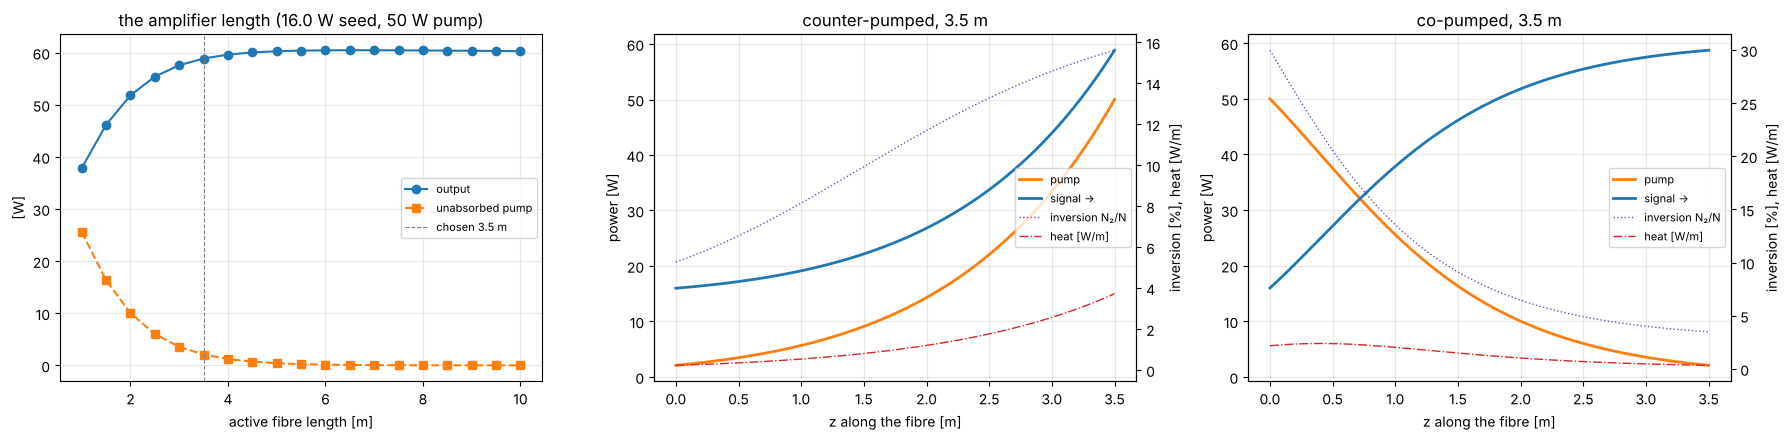

In [5]:
t0 = time.time()
AC = sf.amplifier_length_choice(S_OSC.output_W, PUMP_AMP, n=sf.N_SWEEP)
ALEN = AC["chosen_length"]
print(f"amplifier length: the best {AC['best_length']:g} m; chosen {ALEN:g} m ({AC['rule']}): {AC['chosen_output_W']:.1f} W  [{time.time() - t0:.0f} s]")
AMP = sf.amplifier(ALEN, "counter"); S_AMP = AMP.solve(S_OSC.output_W, PUMP_AMP, n=sf.N_FINE)
S_CO = sf.amplifier(ALEN, "co").solve(S_OSC.output_W, PUMP_AMP, n=sf.N_FINE)
AT = pd.DataFrame({"counter-pumped": S_AMP.to_dict(), "co-pumped": S_CO.to_dict()}).drop(index=["note"]); display(AT.astype(float).round(3))
print(f"the stage: {S_OSC.output_W:.1f} W in, {S_AMP.output_W:.1f} W out ({S_AMP.gain_db:.1f} dB), {S_AMP.unabsorbed_W:.1f} W of pump left; "
      f"whole device: {PUMP_OSC + PUMP_AMP:.0f} W of pump → {S_AMP.output_W:.1f} W, {S_AMP.output_W / (PUMP_OSC + PUMP_AMP):.0%}")
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
sfd.length_view(AC, ax=axs[0], title=f"the amplifier length ({S_OSC.output_W:.1f} W seed, {PUMP_AMP:.0f} W pump)")
sfd.evolution_view(S_AMP, ax=axs[1], title=f"counter-pumped, {ALEN:g} m")
sfd.evolution_view(S_CO, ax=axs[2], title=f"co-pumped, {ALEN:g} m")
plt.tight_layout(); plt.savefig(OUT / "amplifier.png", dpi=110); plt.show()

## 4. The coil and the limits

Marcuse's bend loss of LP₀₁ against the coil radius for both fibres, and the smallest radius at which the whole length
loses no more than 0.05 dB — the spool's size. (The 20/125's LP₁₁ is bent out at a radius the fundamental survives; that
budget is the few-mode stripping of S.5.4's open item, not this curve.) The limits: stimulated Raman scattering against
the signal in the amplifier fibre (Smith's 16 A_eff/g_R L_eff — far away for CW watts, the first wall for pulses), and the
core's temperature at the hottest metre for four coolings: still air, a plate, a cooled spool, a water-cooled groove.

coil radius for ≤ 0.05 dB over the length: {'oscillator': '46 mm', 'amplifier': '52 mm'}
SRS threshold: oscillator fibre 1934 W (109× the circulating power), amplifier fibre 11584 W (197× the output); Stokes line 1123 nm


,oscillator (0.60 W/m peak),amplifier (3.73 W/m peak)
still air,76.8,477.8
on a plate,15.8,98.0
on a cooled spool,2.1,12.6
in a water-cooled groove,0.9,5.4


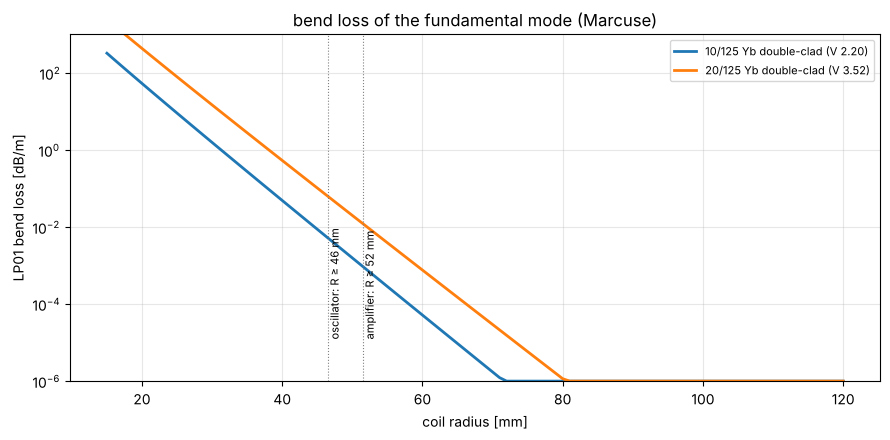

In [6]:
COILS = {sf.FIBRE_OSC.name: sf.coil(sf.FIBRE_OSC), sf.FIBRE_AMP.name: sf.coil(sf.FIBRE_AMP)}
RADII = {"oscillator": sf.coil_radius_for(sf.FIBRE_OSC, LEN), "amplifier": sf.coil_radius_for(sf.FIBRE_AMP, ALEN)}
print("coil radius for ≤ 0.05 dB over the length:", {k: f"{v * 1e3:.0f} mm" for k, v in RADII.items()})
LIM_OSC = sf.limits(sf.FIBRE_OSC, LEN, S_OSC, S_OSC.Ps_fwd[-1])
LIM_AMP = sf.limits(sf.FIBRE_AMP, ALEN, S_AMP, S_AMP.output_W)
print(f"SRS threshold: oscillator fibre {LIM_OSC['srs']['P_threshold_W']:.0f} W ({LIM_OSC['srs_margin']:.0f}× the circulating power), amplifier fibre "
      f"{LIM_AMP['srs']['P_threshold_W']:.0f} W ({LIM_AMP['srs_margin']:.0f}× the output); Stokes line {LIM_AMP['srs']['stokes_wavelength'] * 1e9:.0f} nm")
TEMP = pd.DataFrame({f"{name} ({lim['peak_heat_per_m']:.2f} W/m peak)": {c: t["dT_core_to_sink"] for c, t in lim["temperatures"].items()}
                     for name, lim in (("oscillator", LIM_OSC), ("amplifier", LIM_AMP))}); display(TEMP.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5)); sfd.coil_view(COILS, ax=ax, budgets=RADII)
plt.tight_layout(); plt.savefig(OUT / "coil.png", dpi=110); plt.show()

## 5. The beam out and the delivery train

The LP₀₁ leaving the amplifier's angled cleave or end cap: a 9 µm waist diverging at 2.2°, M² 1.05 — no thermal lens, no
cavity alignment, the fibre's geometry alone. Svarog's delivery train sized for the same 1 mm collimated radius, the same
stand-off and 50 mm focusing lens, so the work spots compare: the collimator is a 25 mm lens instead of the rod's 634 mm one.

waist at the fibre end [µm]               8.963
half-angle divergence [mrad]             39.899
M²                                        1.050
collimator f [mm]                        25.205
collimated radius [mm]                    1.007
focusing lens f [mm]                     50.000
work spot radius [µm]                    17.775
depth of focus 2 z_R [mm]                 1.777
intensity at the work spot [kW/cm²]    5932.288
Name: delivery, dtype: float64

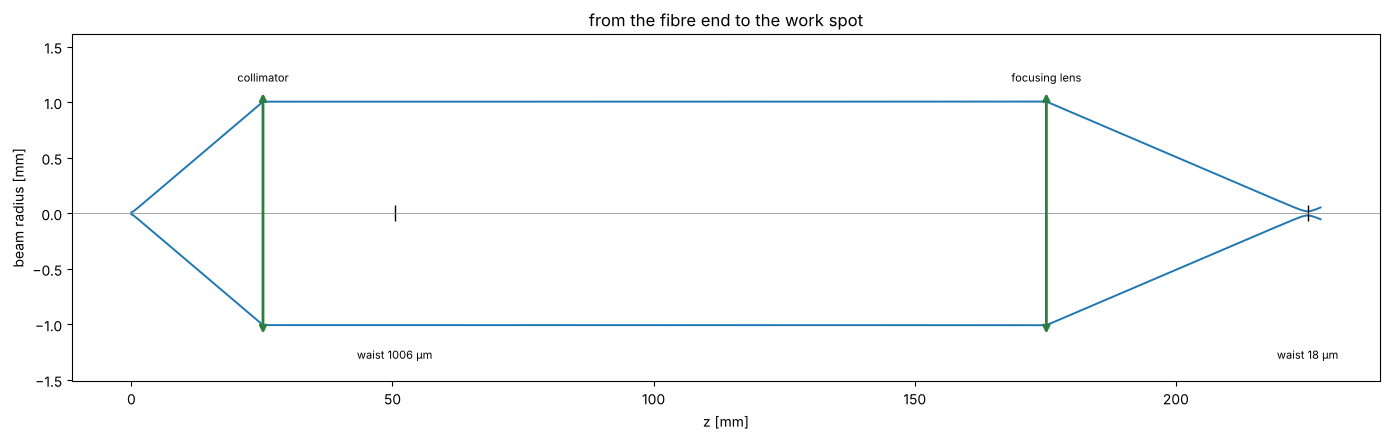

In [7]:
BEAM = sf.beam_out(sf.FIBRE_AMP)
DL = sf.delivery(BEAM)
display(pd.Series({"waist at the fibre end [µm]": BEAM.w0 * 1e6, "half-angle divergence [mrad]": BEAM.divergence * 1e3, "M²": BEAM.m2,
                   "collimator f [mm]": DL["f_collimator"] * 1e3, "collimated radius [mm]": DL["w_collimated"] * 1e3, "focusing lens f [mm]": 50.0,
                   "work spot radius [µm]": DL["work_spot"] * 1e6, "depth of focus 2 z_R [mm]": DL["depth_of_focus"] * 1e3,
                   "intensity at the work spot [kW/cm²]": S_AMP.output_W / (math.pi * DL["work_spot"] ** 2) / 1e7}, name="delivery").round(3))
fig, ax = plt.subplots(figsize=(14, 4.5)); svd.train_view(DL["trace"], ax=ax, title="from the fibre end to the work spot", scale_w=1e3, unit="mm")
plt.tight_layout(); plt.savefig(OUT / "delivery.png", dpi=110); plt.show()

## 6. Against the rod

The oscillator at the rod's work point (20 W launched) against notebook 46's record: what each gives, what it costs in
heat, what its beam is, and what each is sensitive to.

In [8]:
CMP = sf.against_the_rod(R46, S_OSC, TH, PC["slope"], DL, BEAM, PUMP_OSC)
VS = pd.DataFrame(CMP["rows"], index=["Svarog-fiber (oscillator)", "Svarog (rod, revision D)"]).T; display(VS.round(3))
if not CMP["have_rod"]:
    print("the rod's column is empty: notebook 46's report was not found")
for k, v in CMP["sensitivities"].items():
    print(f"{k}: sensitive to {v}")

,Svarog-fiber (oscillator),"Svarog (rod, revision D)"
pump at the work point [W],20.000,20.000
output [W],15.982,11.317
optical efficiency,0.799,0.566
threshold [W],0.232,0.939
slope,0.808,0.594
heat in the gain medium [W],2.141,5.890
beam waist [µm],8.963,214.763
beam divergence [mrad],39.899,1.577
M²,1.050,1.000
work spot radius [µm],17.775,16.664


fibre: sensitive to the gratings' wavelengths and temperature, splice losses, the pump diodes' wavelength against the 976 nm peak, bend loss, SRS at high power
rod: sensitive to the thermal lens (η_heat, the pump spot), the cavity's alignment, the mode–pump overlap, the rod's fracture limit


## 7. The record

The oscillator and the amplifier (Hyperion objects), the pumps, the beam and the delivery train in
`designs/data/svarog_fiber_design.json`; this notebook's tables in `designs/data/reports/47_svarog_fiber.json`. The exit gate
checks both were written by this run and stamps them.

In [9]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = sf.design_record(LEN, OSC.R_oc, PUMP_OSC, ALEN, PUMP_AMP, BEAM, DL)
hy.save_design(DATA / "svarog_fiber_design.json", REC, notes=f"Svarog-fiber: {LEN:g} m oscillator at {PUMP_OSC:.0f} W, {ALEN:g} m amplifier at {PUMP_AMP:.0f} W (notebook 47)")
REPORT = {"meta": {"notebook": "47_svarog_fiber", "pump_osc_W": PUMP_OSC, "pump_amp_W": PUMP_AMP, "wavelength": sf.LAM, "pump_wavelength": sf.LAM_P, "debug": DEBUG,
                   "rod_report": str(R46_PATH) if R46 else None},
          "fibres": FIB.to_dict(orient="index"),
          "oscillator": {"length": LEN, "R_hr_effective": OSC.R_hr, "R_oc": OSC.R_oc, "length_choice": {k: v for k, v in LC.items()}, "coupler": CC.to_dict(orient="index"),
                         "threshold_W": TH, "slope": PC["slope"], "power_curve": {k: v for k, v in PC.items()}, **S_OSC.to_dict()},
          "amplifier": {"length": ALEN, "seed_W": S_OSC.output_W, "length_choice": {k: v for k, v in AC.items()}, "counter": S_AMP.to_dict(), "co": S_CO.to_dict()},
          "coil": {"radius_for_0.05dB": RADII, "V": {k: c["V"] for k, c in COILS.items()}},
          "limits": {"oscillator": {"srs": LIM_OSC["srs"], "srs_margin": LIM_OSC["srs_margin"], "temperatures": LIM_OSC["temperatures"]},
                     "amplifier": {"srs": LIM_AMP["srs"], "srs_margin": LIM_AMP["srs_margin"], "temperatures": LIM_AMP["temperatures"]}},
          "beam_out": BEAM.to_dict(), "delivery": {k: v for k, v in DL.items() if k not in ("train", "trace")},
          "against_the_rod": {"rows": {k: list(v) for k, v in CMP["rows"].items()}, "have_rod": CMP["have_rod"], "sensitivities": CMP["sensitivities"]}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "47_svarog_fiber.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "svarog_fiber_design.json", "and", DATA / "reports" / "47_svarog_fiber.json")

written designs/data/svarog_fiber_design.json and designs/data/reports/47_svarog_fiber.json


In [10]:
STAMPS = GATE.leave()          # svarog_fiber_design.json and the report, written by this run and stamped

## 8. Reading it

- **The fibre has no thermal lens and no alignment.** Where the rod's design was the fight between the pump's lens and the
  cavity's window, the fibre's is a length and two gratings: the output follows the quantum limit times the coupling, the
  threshold is a fifth of a watt, and the beam is the fibre's mode whatever the pump does. Its own sensitivities are the
  gratings' wavelength (temperature-tuned), the splices, the diode wavelength against the 976 nm absorption peak, and the coil.
- **The length is a cost-and-margin choice, not a physics one**, once the fibre absorbs ~90 % of the pump: the curve is flat,
  and the shorter fibre has the higher SRS threshold and the easier coil; the unabsorbed pump must be stripped at the
  splice (a cladding-mode stripper, S.3 for the fibre).
- **Heat is spread**, a few watts per metre at the pump end — harmless on a cooled spool, not in still air. The amplifier's
  pump end is the hot metre and the photodarkening end; counter-pumping puts the strongest inversion under the strongest signal.
- **At the same 20 W, the fibre gives half again the rod's output** and a diffraction-limited beam into a 25 mm collimator; the
  rod gives a free-space cavity to put a Q-switch or a doubling crystal in, and no fibre to damage at high peak power. The
  limits that are not here — ASE of a weak seed, the few-mode coil's stripping budget, SRS and self-focusing of pulses — are
  the fibre's next items in `svarog_todo.md`.